**<small><i>This notebook was put together by [John Krohn](https://github.com/jonkrohn/ML-foundations/tree/master/notebooks). Source and license info is on [GitHub](https://github.com/jonkrohn/ML-foundations).</i></small>**

## Linear Algebra Review with Numpy Part 1


Tensors are machine learning(ML) genralizations of vectors and matrices to any number of dimensions.


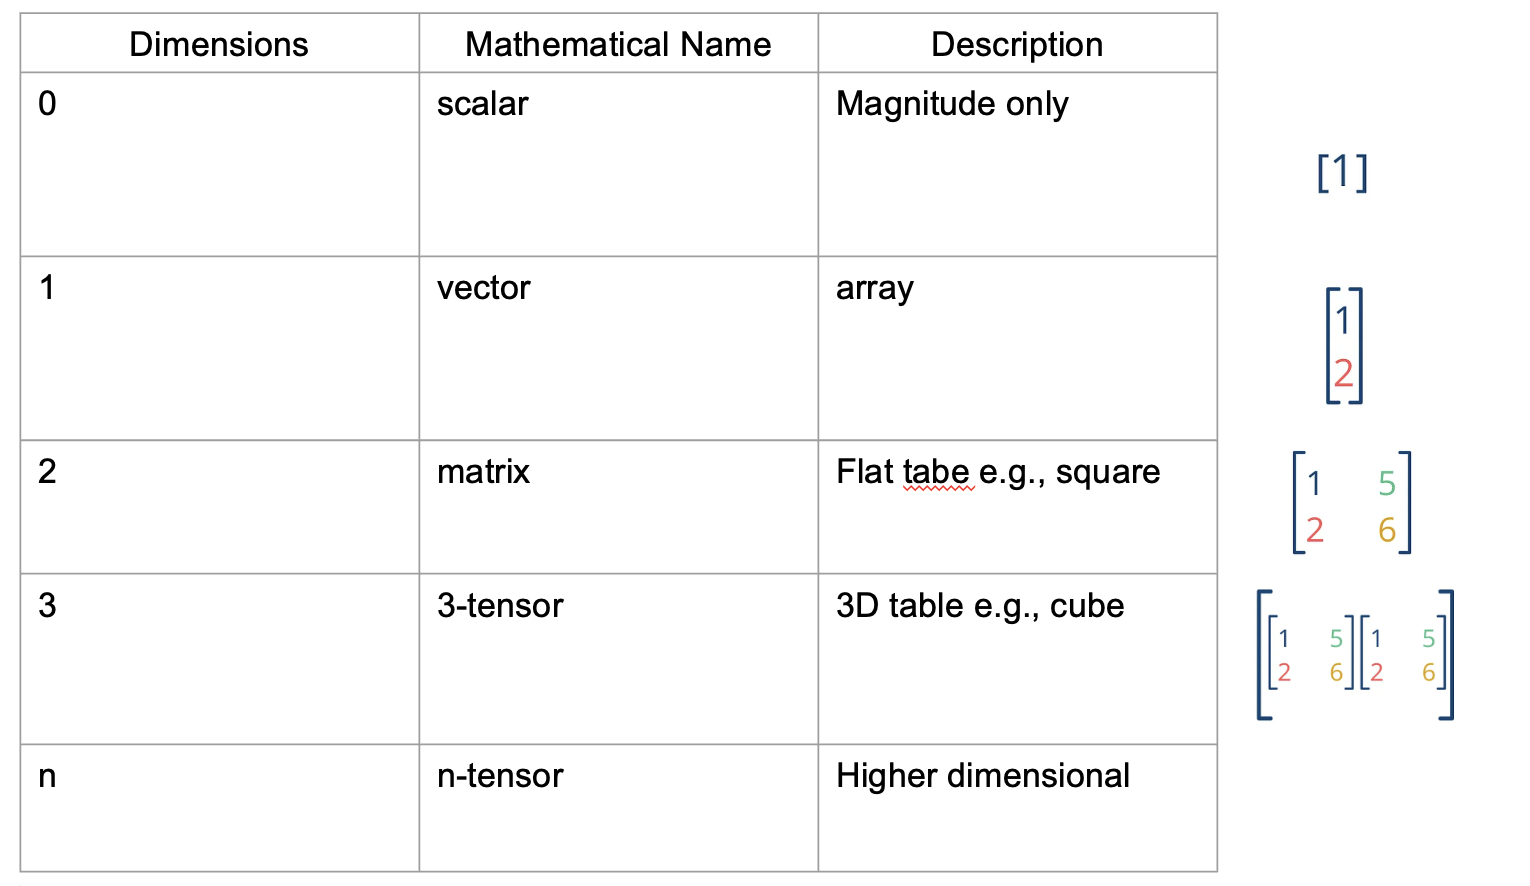

## 🔢 Understanding Scalars

A **scalar** is the simplest form of data used in programming and mathematics — a **single number**.

- **Dimensions**: Scalars have **no dimensions** — they are just single values.
- **Notation**: Typically written in **lowercase, italic** letters — for example, _x_.
- **Typing**: Like all other tensors, scalars should have a specified type (e.g., `int`, `float32`).

### 🧮 Example:

- _x_ = 3  
- _y_ = 2.5  
These are both scalars, one of integer type and the other a floating point.

> Scalars are the building blocks for higher-dimensional tensors like vectors and matrices.


### Scalars (Rank 0 Tensors) in Base Python

In [ ]:
x = 25
x

In [ ]:
type(x) # if we'd like more specificity (e.g., int16, uint8), we need NumPy or another numeric library

In [ ]:
y = 3

In [ ]:
py_sum = x + y
py_sum

In [ ]:
type(py_sum)

In [ ]:
x_float = 25.0
float_sum = x_float + y
float_sum

In [ ]:
type(float_sum)

## Understanding Vectors

A **vector** is a one-dimensional array of numbers that can be used to represent a point in space.

- **Notation**: Vectors are typically written in **lowercase, bold, italic** letters — for example, **_x_**.
- **Indexing**: Vectors are ordered, so each element can be accessed by its position (index).
  - The elements themselves are **scalars** (not bold).
  - For example, the second element of the vector **_x_** is written as _x₂_.

### Spatial Representation
Vectors are often used to represent a **location** in space:

- A vector of length **2** indicates a point in **2D space** (a plane).
- A vector of length **3** indicates a point in **3D space** (a cube).
- A vector of length **_n_** indicates a point in **_n_-dimensional space**.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

### Vectors (Rank 1 Tensors) in NumPy

In [ ]:
x = np.array([25, 2, 5]) # type argument is optional, e.g.: dtype=np.float16
x

In [ ]:
len(x)

In [ ]:
x.shape

In [ ]:
type(x)

In [ ]:
x[0] # zero-indexed

In [ ]:
type(x[0])

### Vector Transposition

In [ ]:
# Transposing a regular 1-D array has no effect...
x_t = x.T
x_t

In [ ]:
x_t.shape

In [ ]:
# ...but it does we use nested "matrix-style" brackets:
y = np.array([[25, 2, 5]])
y

In [ ]:
y.shape

In [ ]:
# ...but can transpose a matrix with a dimension of length 1, which is mathematically equivalent:
y_t = y.T
y_t

In [ ]:
y_t.shape # this is a column vector as it has 3 rows and 1 column

In [ ]:
# Column vector can be transposed back to original row vector:
y_t.T

In [ ]:
y_t.T.shape

### Zero Vectors

Have no effect if added to another vector

In [ ]:
z = np.zeros(3)
z

##Vector Norms

Vectors represent a **magnitude** and **direction** from the origin.  



For example, the vector:

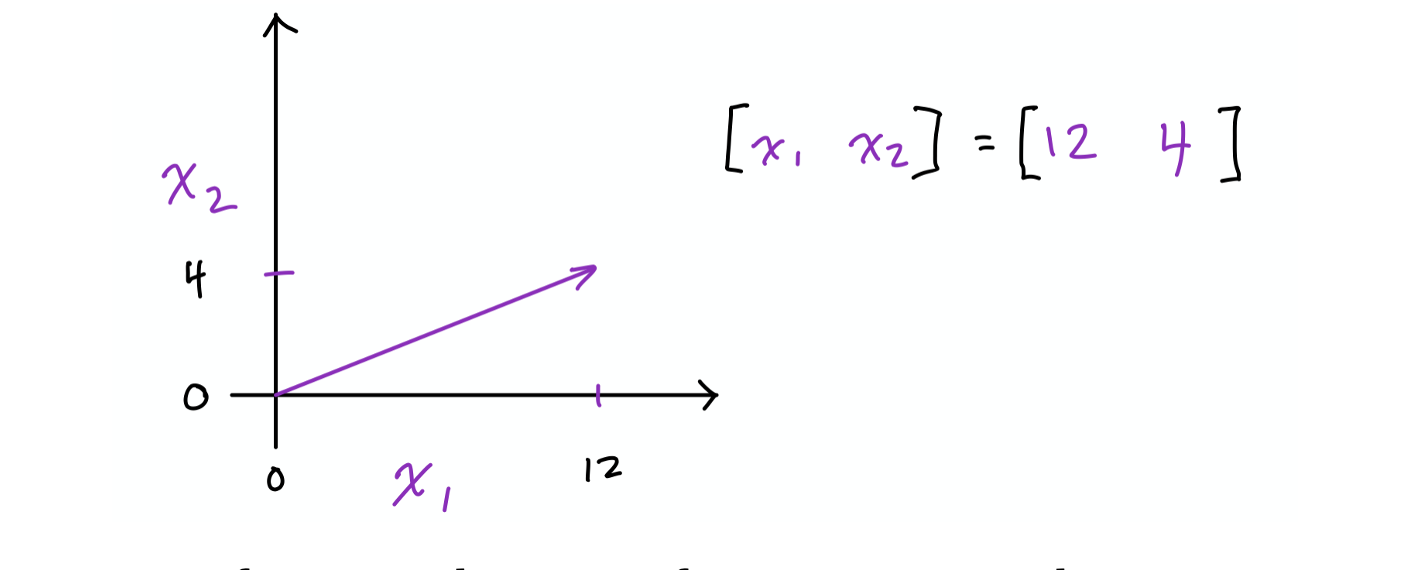

###  What is a Norm?

A **norm** is a function that quantifies the **magnitude (length)** of a vector.  

It answers the question:  
> _How far is the vector from the origin?_



##  Common Norms

##  L² Norm (Euclidean Norm)

The **L² norm** measures the straight-line (Euclidean) distance from the origin to the vector's point in space.



### $L^2$ Norm

Described by:


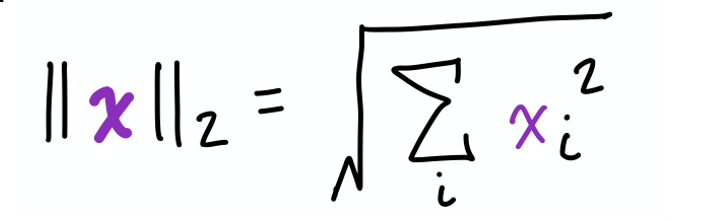

- This is the most common norm in machine learning.
- It is often written simply as \(\|\mathbf{x}\|\) when the context is clear.
 UNIT VECTOR INFO SLIDE 35

In [ ]:
x

In [ ]:
(25**2 + 2**2 + 5**2)**(1/2)

In [ ]:
np.linalg.norm(x)

So, if units in this 3-dimensional vector space are meters, then the vector $x$ has a length of 25.6m

### $L^1$ Norm

##  L¹ Norm (Manhattan Norm)

The **L¹ norm** measures distance by moving only along coordinate axes — like navigating a grid of city blocks.


Described by:

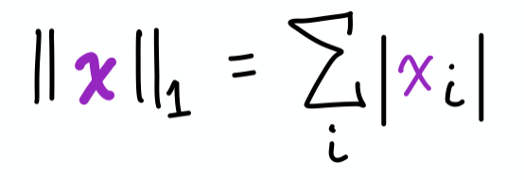


- Measures the total absolute distance from the origin.
- Also known as the **Manhattan norm** or **taxicab norm**.
- Commonly used in machine learning when **sparsity** is important.
- Unlike the L² norm, it:
  - Varies **linearly** with the components.
  - Emphasizes the difference between **zero and non-zero** values.
  - Encourages solutions with **fewer non-zero entries** (e.g., Lasso regression).


In [ ]:
x

In [ ]:
np.abs(25) + np.abs(2) + np.abs(5)

### Squared $L^2$ Norm


The **squared L² norm** is simply the square of the Euclidean norm. It removes the square root from the standard L² norm:

Described by:

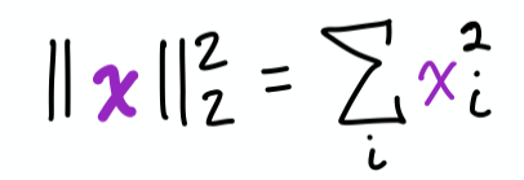

Why Use It?
-  **Computationally cheaper** than the L² norm — no need to compute a square root.
- The **derivative is simpler**:  
  Each element’s gradient depends only on that element (not the full vector).
- Commonly used as a **loss function** in regression problems (e.g., Mean Squared Error).

Limitations
-  **Grows slowly near the origin**, making it **less sensitive to small values**.
-  Not ideal when distinguishing between _zero_ and _near-zero_ values is important.

> Useful for optimization and training machine learning models where performance matters more than sensitivity to tiny magnitudes.


In [ ]:
x

In [ ]:
(25**2 + 2**2 + 5**2)

In [ ]:
# we'll cover tensor multiplication more soon but to prove point quickly:
np.dot(x, x)

### Max Norm

The **max norm** measures the **largest absolute value** among a vector’s elements.


Described by:

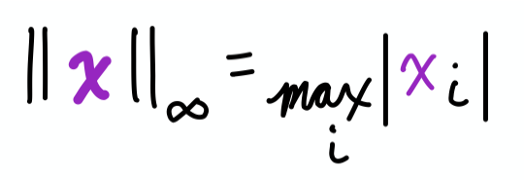

- Also called the **max norm** or **chebyshev norm**.
- Returns the value of the **largest-magnitude component** in the vector.
- Final norm we'll discuss, but it appears **frequently in ML algorithms**.

 When to Use

- Useful when you care about the **worst-case deviation**.
- Helps control the **largest possible error** in optimization and adversarial settings.

> Use max norm when the **largest component dominates your metric**, or when bounding extremes is more important than total or average distance.

In [ ]:
x

In [ ]:
np.max([np.abs(25), np.abs(2), np.abs(5)])

### Orthogonal Vectors

##  Orthogonal and Orthonormal Vectors

### 🧾 Orthogonal Vectors

- Two vectors **x** and **y** are **orthogonal** if their dot product is zero:  
  $$
  x^{\mathsf T} y = 0
  $$

- This means they are at a **90° angle** to each other *(assuming non-zero norms)*.
- In **n-dimensional space**, the maximum number of **mutually orthogonal vectors** is **n** *(again, assuming non-zero norms)*.
- Each has **unit norm** (‖x‖ = 1)
- Example: standard basis vectors (e₁, e₂, ..., eₙ)




In [ ]:
i = np.array([1, 0])
i

In [ ]:
j = np.array([0, 1])
j

In [ ]:
np.dot(i, j) # detail on the dot operation coming up...

### Matrices (Rank 2 Tensors) in NumPy

##Matrices



### Basic Notation and Structure

- A **matrix** is a **two-dimensional array of numbers**.
- Typically denoted using **bold, uppercase italics**, e.g., **𝐗**.
- Shape notation prioritizes height (rows) over width (columns):  
  - If **𝐗** has 3 rows and 2 columns, its shape is (3, 2)

####  Elements and Access
- Individual elements are **scalars**, written as uppercase italics (no bold).
- For example, the element in the **first row, second column** of matrix 𝐗 is written as:  
  $$
  X_{1,2}
  $$

####  Slicing with Colons
- A colon `:` is used to select all elements from a row or column:

| Notation   | Meaning                            |
|------------|-------------------------------------|
| `X[:, 1]`  | Left column of matrix **X**         |
| `X[2, :]`  | Middle (third) row of matrix **X**  |

> Note: Python indexing is zero-based, so these examples assume 1-based math notation for clarity. In Python, `X[2, :]` would be the **third** row.


In [ ]:
# Use array() with nested brackets:
X = np.array([[25, 2], [5, 26], [3, 7]])
X

In [ ]:
X.shape

In [ ]:
X.size

In [ ]:
# Select left column of matrix X (zero-indexed)
X[:,0]

In [ ]:
# Select middle row of matrix X:
X[1,:]

In [ ]:
# Another slicing-by-index example:
X[0:2, 0:2]

## Segment 2: Common Tensor Operations

### Tensor Transposition

The **transpose** operation flips the axes of a tensor across its **main diagonal**.

-Transpose of scalar is itself, e.g



The **transpose** operation flips the axes of a tensor across its **main diagonal**.



Transpose **_Xᵀ_**:

\[
X^\top = \begin{bmatrix}
X_{1,1} & X_{2,1} & X_{3,1} \\
X_{1,2} & X_{2,2} & X_{3,2}
\end{bmatrix}
\]

This "flips" the matrix across its **main diagonal**.

---

> ✅ Transposition is fundamental for many linear algebra operations, including dot products, eigendecomposition, and reshaping data for models.


In [ ]:
X

In [ ]:
X.T

### Basic Arithmetical Properties

Adding or multiplying with scalar applies operation to all elements and tensor shape is retained:

In [ ]:
X*2

In [ ]:
X+2

In [ ]:
X*2+2

If two tensors have the same size, operations are often by default applied element-wise. This is **not matrix multiplication**, which we'll cover later, but is rather called the **Hadamard product** or simply the **element-wise product**.

The mathematical notation is $A \odot X$

In [ ]:
X

In [ ]:
A = X+2
A

In [ ]:
A + X

In [ ]:
A * X

### Reduction

Calculating the sum across all elements of a tensor is a common operation. For example:

* For vector ***x*** of length *n*, we calculate $\sum_{i=1}^{n} x_i$
* For matrix ***X*** with *m* by *n* dimensions, we calculate $\sum_{i=1}^{m} \sum_{j=1}^{n} X_{i,j}$

In [ ]:
X

In [ ]:
X.sum()

In [ ]:
# Can also be done along one specific axis alone, e.g.:
X.sum(axis=0) # summing over all rows (i.e., along columns)

In [ ]:
X.sum(axis=1) # summing over all columns (i.e., along rows)

Many other operations can be applied with reduction along all or a selection of axes, e.g.:

* maximum
* minimum
* mean
* product

They're fairly straightforward and used less often than summation, so you're welcome to look them up in library docs if you ever need them.

### The Dot Product

If we have two vectors (say, ***x*** and ***y***) with the same length *n*, we can calculate the dot product between them. This is annotated several different ways, including the following:

* $x \cdot y$
* $x^Ty$
* $\langle x,y \rangle$

Regardless which notation you use (I prefer the first), the calculation is the same; we calculate products in an element-wise fashion and then sum reductively across the products to a scalar value. That is, $x \cdot y = \sum_{i=1}^{n} x_i y_i$

The dot product is ubiquitous in deep learning: It is performed at every artificial neuron in a deep neural network, which may be made up of millions (or orders of magnitude more) of these neurons.

In [ ]:
x

In [ ]:
y = np.array([0, 1, 2])
y

In [ ]:
25*0 + 2*1 + 5*2

In [ ]:
np.dot(x, y)

### Solving Linear Systems

In the **Substitution** example, the two equations in the system are:
$$ y = 3x $$
$$ -5x + 2y = 2 $$

The second equation can be rearranged to isolate $y$:
$$ 2y = 2 + 5x $$
$$ y = \frac{2 + 5x}{2} = 1 + \frac{5x}{2} $$

In [ ]:
x = np.linspace(-10, 10, 1000) # start, finish, n points

In [ ]:
y1 = 3 * x

In [ ]:
y2 = 1 + (5*x)/2

In [ ]:
fig, ax = plt.subplots()
plt.xlabel('x')
plt.ylabel('y')
ax.set_xlim([0, 3])
ax.set_ylim([0, 8])
ax.plot(x, y1, c='green')
ax.plot(x, y2, c='brown')
plt.axvline(x=2, color='purple', linestyle='--')
_ = plt.axhline(y=6, color='purple', linestyle='--')

In the **Elimination** example, the two equations in the system are:
$$ 2x - 3y = 15 $$
$$ 4x + 10y = 14 $$

Both equations can be rearranged to isolate $y$. Starting with the first equation:
$$ -3y = 15 - 2x $$
$$ y = \frac{15 - 2x}{-3} = -5 + \frac{2x}{3} $$

Then for the second equation:
$$ 4x + 10y = 14 $$
$$ 2x + 5y = 7 $$
$$ 5y = 7 - 2x $$
$$ y = \frac{7 - 2x}{5} $$

In [ ]:
y1 = -5 + (2*x)/3

In [ ]:
y2 = (7-2*x)/5

In [ ]:
fig, ax = plt.subplots()
plt.xlabel('x')
plt.ylabel('y')

# Add x and y axes:
plt.axvline(x=0, color='lightgray')
plt.axhline(y=0, color='lightgray')

ax.set_xlim([-2, 10])
ax.set_ylim([-6, 4])
ax.plot(x, y1, c='green')
ax.plot(x, y2, c='brown')
plt.axvline(x=6, color='purple', linestyle='--')
_ = plt.axhline(y=-1, color='purple', linestyle='--')

## Segment 3: Matrix Properties

### Frobenius Norm

- The **Frobenius norm** is analogous to the **L2 norm** of a vector.
- It measures the **size** of a matrix in terms of **Euclidean distance**.
- Interpreted as the **sum of the magnitudes of all vectors** (rows or columns) in the matrix **X**.



![Matrix Notation](https://drive.google.com/uc?export=view&id=1gQIiYEl7oA6ksq1An5HHehqjosH3yNPQ)


It’s equivalent to flattening the matrix into a vector and taking the L2 norm.


In [ ]:
X = np.array([[1, 2], [3, 4]])
X

In [ ]:
(1**2 + 2**2 + 3**2 + 4**2)**(1/2)

In [ ]:
np.linalg.norm(X) # same function as for vector L2 norm

### Matrix Multiplication (with a Vector)

In [ ]:
A = np.array([[3, 4], [5, 6], [7, 8]])
A

In [ ]:
b = np.array([1, 2])
b

In [ ]:
np.dot(A, b) # even though technically dot products are between vectors only

### Matrix Multiplication (with Two Matrices)

In [ ]:
A

In [ ]:
B = np.array([[1, 9], [2, 0]])
B

In [ ]:
np.dot(A, B)

Note that matrix multiplication is not "commutative" (i.e., $AB \neq BA$) so uncommenting the following line will throw a size mismatch error:

In [ ]:
# np.dot(B, A)

### Symmetric Matrices

In [ ]:
X_sym = np.array([[0, 1, 2], [1, 7, 8], [2, 8, 9]])
X_sym

In [ ]:
X_sym.T

In [ ]:
X_sym.T == X_sym

### Identity Matrices



- A symmetric matrix where:
  - Every element along the main diagonal is **1**
  - All other elements are **0**
- Notation: `Iₙ`, where `n` is the height (or width)
- A vector `x` of length `n` is **unchanged** when multiplied by `Iₙ`:



 ![Identity Matrix](https://drive.google.com/uc?export=view&id=1kX0U3wQx8y9QORYcUHhAxwdYXyHf4tzr)


### Matrix Inversion



- The **inverse** of a square matrix `A` is denoted as `A⁻¹`.
- A matrix is **invertible** (or **non-singular**) if:

  $$
A \cdot A^{-1} = A^{-1} \cdot A = I
$$

  where `I` is the identity matrix.

- Only **square matrices** with **non-zero determinant** have inverses.

- The inverse "undoes" the transformation of the original matrix:
  $$
A^{-1} \cdot A \cdot x = x
$$
  
**Notes:**
- Not all matrices are invertible (those that aren't are called **singular**).
- In numerical computation, it's often better to use **matrix solvers** (`np.linalg.solve`) instead of directly computing the inverse (`np.linalg.inv`) for better stability and efficiency.

In [ ]:
X = np.array([[4, 2], [-5, -3]])
X

In [ ]:
Xinv = np.linalg.inv(X)
Xinv

As a quick aside, let's prove that $X^{-1}X = I_n$ as per the slides:

In [ ]:
np.dot(Xinv, X)

...and now back to solving for the unknowns in $w$:

In [ ]:
y = np.array([4, -7])
y

In [ ]:
w = np.dot(Xinv, y)
w

Show that $y = Xw$:

In [ ]:
np.dot(X, w)

**Geometric Visualization**

Recalling from the slides that the two equations in the system are:
$$ 4b + 2c = 4 $$
$$ -5b - 3c = -7 $$

Both equations can be rearranged to isolate a variable, say $c$. Starting with the first equation:
$$ 4b + 2c = 4 $$
$$ 2b + c = 2 $$
$$ c = 2 - 2b $$

Then for the second equation:
$$ -5b - 3c = -7 $$
$$ -3c = -7 + 5b $$
$$ c = \frac{-7 + 5b}{-3} = \frac{7 - 5b}{3} $$

In [ ]:
b = np.linspace(-10, 10, 1000) # start, finish, n points

In [ ]:
c1 = 2 - 2*b

In [ ]:
c2 = (7-5*b)/3

In [ ]:
fig, ax = plt.subplots()
plt.xlabel('b', c='darkorange')
plt.ylabel('c', c='brown')

plt.axvline(x=0, color='lightgray')
plt.axhline(y=0, color='lightgray')

ax.set_xlim([-2, 3])
ax.set_ylim([-1, 5])
ax.plot(b, c1, c='purple')
ax.plot(b, c2, c='purple')
plt.axvline(x=-1, color='green', linestyle='--')
_ = plt.axhline(y=4, color='green', linestyle='--')

### Matrix Inversion Where No Solution

In [ ]:
X = np.array([[-4, 1], [-8, 2]])
X

In [ ]:
# Uncommenting the following line results in a "singular matrix" error
# Xinv = np.linalg.inv(X)

Feel free to try inverting a non-square matrix; this will throw an error too.

**Return to slides here.**

### Orthogonal Matrices

- A square matrix **Q** ∈ ℝⁿˣⁿ is **orthogonal** if its columns (and rows) form an orthonormal set:
  $$
  Q^{\mathsf T} Q = Q Q^{\mathsf T} = I_n
  $$

##### ✅ Properties
| Property                | Description                                             |
|-------------------------|---------------------------------------------------------|
| **Length-preserving**   | ‖Qx‖ = ‖x‖ for any vector x                             |
| **Angle-preserving**    | Angles between vectors are unchanged                    |
| **Determinant**         | det(Q) = ±1                                             |
| **Transpose is inverse**| Q⁻¹ = Qᵀ                                                |
| **Geometric meaning**   | det = +1 → rotation; det = –1 → rotation + reflection   |


In [ ]:
I = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]])
I

In [ ]:
column_1 = I[:,0]
column_1

In [ ]:
column_2 = I[:,1]
column_2

In [ ]:
column_3 = I[:,2]
column_3

In [ ]:
np.dot(column_1, column_2)

In [ ]:
np.dot(column_1, column_3)

In [ ]:
np.dot(column_2, column_3)

We can use the `np.linalg.norm()` method from earlier in the notebook to demonstrate that each column of $I_3$ has unit norm:

In [ ]:
np.linalg.norm(column_1)

In [ ]:
np.linalg.norm(column_2)

In [ ]:
np.linalg.norm(column_3)

Since the matrix $I_3$ has mutually orthogonal columns and each column has unit norm, the column vectors of $I_3$ are *orthonormal*. Since $I_3^T = I_3$, this means that the *rows* of $I_3$ must also be orthonormal.

Since the columns and rows of $I_3$ are orthonormal, $I_3$ is an *orthogonal matrix*.

## 🛑 End of Lesson 5a: Linear Algebra w/Numpy Part 1

## **Please proceed to Lesson 5b: Linear Algebra w/Numpy part 2 to continue the tutorial.**

Please complete the following Tasks:

- ✅ **Lesson 5 Terminology Quiz**
- ✅ **Lesson 5 Coding (Individual and Group) Exercises**

📩 Submit all solutions to your instructor once complete.